# Modelado v2: riesgo de retraso en la salida (`DepDel15`)

Lee la **capa silver** (salida de `flight_delay_eda_leakage.ipynb`) y compara cuatro modelos candidatos con **las mismas variables**:

| Candidato | Rol |
|---|---|
| Regresión logística | Línea base (propuesta) |
| LightGBM | Modelo principal esperado (propuesta) |
| XGBoost | Comparación con otro *gradient boosting* |
| K-means (tasa por clúster) | Comparación con un enfoque **no supervisado** |

Además se corren, si `RUN_ABLATION` / `RUN_WEIGHTED` están activos, un estudio de qué grupo de variables aporta (ablación) y el experimento de pesos de clase.

**Qué cambió respecto a la versión anterior**

1. **Comparación justa:** los modelos se comparan a *igual presupuesto de alertas* (top 5 / 10 / 20 %) y con **intervalos de confianza por bootstrap** de la diferencia. Un empate estadístico se reporta como empate.
2. **LightGBM con más oportunidad:** más datos de entrenamiento, tasa de aprendizaje menor, menos hojas y regularización más fuerte.
3. **Diagnóstico de deriva:** se repite LR vs LightGBM entrenando en 2022–2023 y evaluando en 2024, para saber si la deriva temporal explica el empate. Además, el mejor modelo se **reentrena con entrenamiento + validación**.
4. **Variables nuevas** (sin usar resultados del propio vuelo): congestión programada, rotación de la aeronave y *estado del día* conocido al momento de predecir (ver sección 3b).
5. **Umbral por costo** (falsa alarma vs retraso no detectado) en lugar de maximizar F1.
6. **Veredicto explícito** al final: el notebook declara cuál es el mejor modelo con una regla fija y estadística.

**Decisiones que se mantienen**

- Partición **cronológica**; el umbral y la parada temprana se deciden en validación, nunca en prueba.
- **Sin rebalancear** los modelos candidatos (propuesta, sección *Modelado*): se protege la calidad de las probabilidades.
- No se usa `Year` como variable: la prueba cae en años posteriores y un árbol no puede extrapolar.

## 0. Configuración

In [3]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.cluster import MiniBatchKMeans
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             log_loss, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [4]:
SILVER_GLOB = "../data/silver/flights/**/*.parquet"
OUT_DIR     = Path("../outputs/outputs_modeling")
TARGET      = "DepDel15"
SEED        = 42

MEMORY_LIMIT = "8GB"
TEMP_DIR     = "duckdb_tmp"

# --- Partición cronológica (fechas inclusivas). Prueba = todo lo posterior a VAL_END. ---
TRAIN_END   = "2024-12-31"
VAL_END     = "2025-08-31"
WARMUP_DAYS = 60            # los primeros días no tienen historial: no se usan para entrenar

# --- Tamaño de las muestras (None = todo el tramo; con 20 M de filas necesitas bastante RAM) ---
N_TRAIN   = 4_000_000
N_EVAL    = 1_000_000       # validación y prueba
N_LOGREG  = 1_000_000       # filas de entrenamiento de la regresión logística
N_KMEANS  = 1_000_000       # filas con las que se ajusta K-means

# --- Patrones históricos y estado del día ---
HIST_WINDOW_DAYS = 30
HIST_SMOOTH      = 50
PRED_HORIZON_MIN = 120      # se predice 120 min antes de la salida programada: el estado del día
                            # (retrasos de vuelos anteriores) solo usa lo ya ocurrido a esa hora

# --- Costos del umbral: costo de un retraso no detectado vs. el de una falsa alarma ---
COST_FP = 1
COST_FN = 3                 # supuesto: perder un retraso cuesta 3 veces una falsa alarma

# --- Modelos ---
LGB_MAX_TREES  = 3000
LGB_EARLY_STOP = 100
K_GRID         = [10, 25, 50, 100]

# --- Significancia (bootstrap pareado sobre una submuestra de prueba) ---
BOOT_ROWS = 300_000
BOOT_N    = 100

# --- Secciones opcionales ---
RUN_ABLATION = True         # LightGBM con distintos grupos de variables
RUN_WEIGHTED = True         # experimento de pesos de clase
RUN_DIAG     = True         # diagnóstico de deriva (entrena 2022-2023, evalúa 2024)
RUN_REFIT    = True         # reentrena el ganador con entrenamiento + validación
N_DIAG_TRAIN = 1_500_000
N_DIAG_EVAL  = 500_000

FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
Path(TEMP_DIR).mkdir(exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 1. Datos (capa silver) y partición cronológica

In [5]:
con = duckdb.connect()
con.execute(f"SET memory_limit = '{MEMORY_LIMIT}'")
con.execute(f"SET temp_directory = '{TEMP_DIR}'")
con.execute(f"""
    CREATE OR REPLACE VIEW silver AS
    SELECT * FROM read_parquet('{SILVER_GLOB}', hive_partitioning = true,
                               hive_types = {{'Year': 'SMALLINT', 'Month': 'TINYINT'}})
""")

n_rows, d_min, d_max = con.sql("SELECT COUNT(*), MIN(FlightDate), MAX(FlightDate) FROM silver").fetchall()[0]
print(f"Silver: {n_rows:,} filas | {d_min} → {d_max}")
assert con.sql(f"SELECT COUNT(*) - COUNT({TARGET}) FROM silver").fetchall()[0][0] == 0, "Hay objetivos nulos en silver"

SPLIT_SQL = (f"CASE WHEN FlightDate <= DATE '{TRAIN_END}' THEN 'train' "
             f"WHEN FlightDate <= DATE '{VAL_END}' THEN 'val' ELSE 'test' END")
split_summary = con.sql(f"""
    SELECT {SPLIT_SQL} AS split, MIN(FlightDate) AS desde, MAX(FlightDate) AS hasta,
           COUNT(*) AS vuelos, AVG({TARGET}) AS tasa_retraso
    FROM silver GROUP BY 1 ORDER BY CASE split WHEN 'train' THEN 0 WHEN 'val' THEN 1 ELSE 2 END
""").df()
split_summary

Silver: 31,833,031 filas | 2022-01-01 → 2026-08-31


,split,desde,hasta,vuelos,tasa_retraso
0,train,2022-01-01,2024-12-31,20301238,0.2084
1,val,2025-01-01,2025-08-31,4610259,0.2226
2,test,2025-09-01,2026-08-31,6921534,0.2294


La tasa de retraso **no es la misma en los tres tramos** (sube hacia 2025–2026): hay deriva temporal. Por eso se vigilan Brier / log loss / calibración, y por eso hay un diagnóstico específico en la sección 12.

## 2. Variables estáticas (conocidas antes de la salida)

In [6]:
# Calendario con la distancia (en días) al feriado federal más cercano, acotada a 10.
cal_dates = pd.date_range(pd.Timestamp(d_min) - pd.Timedelta(days=15), pd.Timestamp(d_max) + pd.Timedelta(days=15))
hol = USFederalHolidayCalendar().holidays(start=cal_dates.min(), end=cal_dates.max()).values.astype("datetime64[D]")
cal_np = cal_dates.values.astype("datetime64[D]")
days_to_hol = np.abs(cal_np[:, None] - hol[None, :]).min(axis=1).astype(float).clip(max=10)
cal_df = pd.DataFrame({"FlightDate": cal_dates.date, "days_to_holiday": days_to_hol})
con.register("cal_df", cal_df)
con.execute("CREATE OR REPLACE TABLE calendar AS SELECT CAST(FlightDate AS DATE) AS FlightDate, days_to_holiday FROM cal_df")

con.execute(f"""
    CREATE OR REPLACE VIEW base AS
    SELECT
        FlightDate,
        CAST({TARGET} AS INTEGER)                              AS {TARGET},
        Reporting_Airline, Origin, Dest, OriginState, DestState, DepTimeBlk,
        Origin || '-' || Dest                                  AS route,
        NULLIF(TRIM(Tail_Number), '')                          AS tail,
        Origin || '_' || CAST(CRSDepTime // 100 AS VARCHAR)    AS origin_hr,
        CAST(Month AS INTEGER)                                 AS Month,
        CAST(DayOfWeek AS INTEGER)                             AS DayOfWeek,
        CAST(DayofMonth AS INTEGER)                            AS DayofMonth,
        CAST(DayOfWeek IN (6, 7) AS INTEGER)                   AS is_weekend,
        DAYOFYEAR(FlightDate)                                  AS day_of_year,
        CAST(CRSDepTime // 100 AS INTEGER)                     AS dep_hour,
        CAST(CRSArrTime // 100 AS INTEGER)                     AS arr_hour,
        CAST((CRSDepTime // 100) * 60 + CRSDepTime % 100 AS INTEGER) AS dep_min,
        CAST((CRSArrTime // 100) * 60 + CRSArrTime % 100 AS INTEGER) AS arr_min,
        CRSElapsedTime, Distance
    FROM silver
""")

CAT_COLS = ["Reporting_Airline", "Origin", "Dest", "route", "OriginState", "DestState", "DepTimeBlk"]
NUM_STATIC = ["Distance", "CRSElapsedTime", "dep_min", "arr_min", "Month", "DayOfWeek", "DayofMonth",
              "day_of_year", "is_weekend", "days_to_holiday"]
con.sql("SELECT * FROM base LIMIT 5").df()

,FlightDate,DepDel15,Reporting_Airline,Origin,Dest,OriginState,DestState,DepTimeBlk,route,tail,origin_hr,Month,DayOfWeek,DayofMonth,is_weekend,day_of_year,dep_hour,arr_hour,dep_min,arr_min,CRSElapsedTime,Distance
0,2022-10-25,0,AA,ORD,SAN,IL,CA,1900-1959,ORD-SAN,N880NN,ORD_19,10,2,25,0,298,19,22,1180,1320,260.0000,"1,723.0000"
1,2022-10-26,0,AA,ORD,SAN,IL,CA,1900-1959,ORD-SAN,N966NN,ORD_19,10,3,26,0,299,19,22,1180,1320,260.0000,"1,723.0000"
2,2022-10-27,0,AA,ORD,SAN,IL,CA,1900-1959,ORD-SAN,N916AN,ORD_19,10,4,27,0,300,19,22,1180,1320,260.0000,"1,723.0000"
3,2022-10-28,0,AA,ORD,SAN,IL,CA,1900-1959,ORD-SAN,N825NN,ORD_19,10,5,28,0,301,19,22,1180,1320,260.0000,"1,723.0000"
4,2022-10-30,0,AA,ORD,SAN,IL,CA,1900-1959,ORD-SAN,N890NN,ORD_19,10,7,30,1,303,19,22,1180,1320,260.0000,"1,723.0000"


## 3. Patrones históricos (sin fuga)

Por llave (aeropuerto de origen, ruta, aerolínea, matrícula, aeropuerto×hora) se acumulan los vuelos **por día** y se usan solo los días **estrictamente anteriores**: `*_rate_all` (todo el historial) y `*_rate_30d` (últimos `HIST_WINDOW_DAYS` días). Se suavizan hacia la tasa global de entrenamiento: `(retrasados + m·prior) / (vuelos + m)`.

In [7]:
PRIOR = con.sql(f"SELECT AVG({TARGET}) FROM base WHERE FlightDate <= DATE '{TRAIN_END}'").fetchall()[0][0]
HIST_KEYS = {"origin": "Origin", "route": "route", "airline": "Reporting_Airline",
             "tail": "tail", "origin_hr": "origin_hr"}
W = HIST_WINDOW_DAYS

t0 = time.time()
for name, col in HIST_KEYS.items():
    con.execute(f"""
        CREATE OR REPLACE TABLE hist_{name} AS
        WITH daily AS (
            SELECT {col} AS k, FlightDate, COUNT(*) AS n, SUM({TARGET}) AS d
            FROM base WHERE {col} IS NOT NULL GROUP BY 1, 2
        )
        SELECT k, FlightDate,
               COALESCE(SUM(n) OVER w_all, 0) AS n_all, COALESCE(SUM(d) OVER w_all, 0) AS d_all,
               COALESCE(SUM(n) OVER w_win, 0) AS n_win, COALESCE(SUM(d) OVER w_win, 0) AS d_win
        FROM daily
        WINDOW w_all AS (PARTITION BY k ORDER BY FlightDate
                         ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING),
               w_win AS (PARTITION BY k ORDER BY FlightDate
                         RANGE BETWEEN INTERVAL {W} DAYS PRECEDING AND INTERVAL 1 DAYS PRECEDING)
    """)
print(f"Tablas de historial listas en {time.time() - t0:,.0f}s | prior (tasa de entrenamiento) = {PRIOR:.4f}")

HIST_COLS = [f"{k}_rate_{s}" for k in HIST_KEYS for s in ("all", f"{W}d")]

Tablas de historial listas en 17s | prior (tasa de entrenamiento) = 0.2084


## 3b. Congestión, rotación de la aeronave y estado del día

Tres grupos de variables nuevas. **Ninguna usa el resultado del propio vuelo ni de vuelos posteriores.**

- **Horario programado** (`SCHED_COLS`, solo itinerario, sin etiquetas): vuelos programados en el mismo aeropuerto de origen en esa hora y en ese día, vuelos programados que llegan al destino en esa hora, número de tramo de la matrícula en el día y tiempo de espera programado desde el tramo anterior.
- **Estado del día** (`STATUS_COLS`): lo que **ya se sabría `PRED_HORIZON_MIN` minutos antes de la salida**.
  - *Aeropuerto*: vuelos del mismo origen y día cuya salida programada fue al menos 15 min antes del corte (así su `DepDel15` ya está determinado) y cuántos se retrasaron.
  - *Aeronave*: tramos anteriores de la misma matrícula y día cuya **llegada programada** es anterior al corte (se usa la llegada, no la salida, porque los husos horarios de dos aeropuertos no son comparables, pero la llegada del tramo anterior y la salida del actual ocurren en el mismo aeropuerto).
- Si el horizonte es 0, la predicción se haría a la hora programada de salida. Si se necesita avisar con más antelación, hay que subir `PRED_HORIZON_MIN` (y las variables de estado pierden información).

> Silver no incluye vuelos cancelados, así que los conteos de congestión subestiman ligeramente el itinerario real.

In [8]:
t0 = time.time()
con.execute("CREATE OR REPLACE TABLE load_origin     AS SELECT Origin, FlightDate, dep_hour, COUNT(*) AS origin_dep_load FROM base GROUP BY ALL")
con.execute("CREATE OR REPLACE TABLE load_origin_day AS SELECT Origin, FlightDate, COUNT(*) AS origin_day_load FROM base GROUP BY ALL")
con.execute("CREATE OR REPLACE TABLE load_dest       AS SELECT Dest, FlightDate, arr_hour, COUNT(*) AS dest_arr_load FROM base GROUP BY ALL")
con.execute("CREATE OR REPLACE TABLE legs AS SELECT tail, FlightDate, dep_min, arr_min, DepDel15 FROM base WHERE tail IS NOT NULL")
con.execute("""
    CREATE OR REPLACE TABLE ap_cum AS
    WITH g AS (SELECT Origin, FlightDate, dep_min, COUNT(*) AS n, SUM(DepDel15) AS d FROM base GROUP BY ALL)
    SELECT Origin, FlightDate, dep_min, SUM(n) OVER w AS cum_n, SUM(d) OVER w AS cum_d
    FROM g
    WINDOW w AS (PARTITION BY Origin, FlightDate ORDER BY dep_min ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
""")
print(f"Tablas de congestión y estado del día listas en {time.time() - t0:,.0f}s")

SCHED_COLS  = ["origin_dep_load", "origin_day_load", "dest_arr_load", "tail_leg_num", "turnaround_min"]
STATUS_COLS = ["prev_leg_delayed", "tail_delayed_known", "tail_known_legs", "origin_known_today", "origin_delay_rate_today"]

Tablas de congestión y estado del día listas en 13s


## 4. Muestras de entrenamiento, validación y prueba

Cada tramo se muestrea por separado (reservoir con semilla) y **después** se unen los patrones históricos, la congestión y el estado del día, que se calculan con todos los vuelos silver.

In [9]:
H = PRED_HORIZON_MIN

def build_split(where, n_rows):
    q = f"SELECT b.*, c.days_to_holiday FROM base b JOIN calendar c USING (FlightDate) WHERE {where}"
    if n_rows:
        q = f"SELECT * FROM ({q}) USING SAMPLE reservoir({n_rows} ROWS) REPEATABLE ({SEED})"
    con.execute(f"""CREATE OR REPLACE TEMP TABLE smp AS
        SELECT ROW_NUMBER() OVER () AS rid, *, dep_min - {H} - 15 AS cut_min, dep_min - {H} AS cut_arr FROM ({q})""")

    # Aeronave: rotación (solo itinerario) y estado de tramos anteriores conocidos al corte.
    con.execute("""CREATE OR REPLACE TEMP TABLE tail_feat AS
        SELECT s.rid,
               COUNT(l.dep_min)                                          AS tail_prev_legs,
               s.dep_min - arg_max(l.arr_min, l.dep_min)                 AS turnaround_raw,
               SUM(l.DepDel15) FILTER (WHERE l.arr_min <= s.cut_arr)     AS tail_delayed_known,
               COUNT(*)        FILTER (WHERE l.arr_min <= s.cut_arr)     AS tail_known_legs,
               arg_max(l.DepDel15, l.dep_min) FILTER (WHERE l.arr_min <= s.cut_arr) AS prev_leg_delayed
        FROM smp s
        LEFT JOIN legs l ON l.tail = s.tail AND l.FlightDate = s.FlightDate AND l.dep_min < s.dep_min
        WHERE s.tail IS NOT NULL
        GROUP BY s.rid, s.dep_min""")

    # Aeropuerto: vuelos del mismo origen y día ya "resueltos" al corte (ASOF sobre acumulados).
    con.execute("""CREATE OR REPLACE TEMP TABLE ap_feat AS
        SELECT s.rid, a.cum_n AS origin_known_today, a.cum_d AS origin_delayed_today
        FROM smp s ASOF LEFT JOIN ap_cum a
          ON s.Origin = a.Origin AND s.FlightDate = a.FlightDate AND s.cut_min >= a.dep_min""")

    joins, cols = [], []
    for name, col in HIST_KEYS.items():
        joins.append(f"LEFT JOIN hist_{name} h_{name} ON h_{name}.k = s.{col} AND h_{name}.FlightDate = s.FlightDate")
        for suffix, (n, d) in {"all": ("n_all", "d_all"), f"{W}d": ("n_win", "d_win")}.items():
            cols.append(f"(COALESCE(h_{name}.{d}, 0) + {HIST_SMOOTH} * CAST({PRIOR} AS DOUBLE)) / "
                        f"(COALESCE(h_{name}.{n}, 0) + {HIST_SMOOTH}) AS {name}_rate_{suffix}")
    sql = f"""
        SELECT s.* EXCLUDE (cut_min, cut_arr, rid), {', '.join(cols)},
               lo.origin_dep_load, lod.origin_day_load, ld.dest_arr_load,
               tf.tail_prev_legs + 1                                   AS tail_leg_num,
               CASE WHEN tf.turnaround_raw >= 0 THEN tf.turnaround_raw END AS turnaround_min,
               tf.prev_leg_delayed, tf.tail_delayed_known, tf.tail_known_legs,
               COALESCE(af.origin_known_today, 0)                      AS origin_known_today,
               COALESCE(af.origin_delayed_today, 0)                    AS origin_delayed_today
        FROM smp s {' '.join(joins)}
        LEFT JOIN load_origin     lo  ON lo.Origin = s.Origin AND lo.FlightDate = s.FlightDate AND lo.dep_hour = s.dep_hour
        LEFT JOIN load_origin_day lod ON lod.Origin = s.Origin AND lod.FlightDate = s.FlightDate
        LEFT JOIN load_dest       ld  ON ld.Dest = s.Dest AND ld.FlightDate = s.FlightDate AND ld.arr_hour = s.arr_hour
        LEFT JOIN tail_feat tf ON tf.rid = s.rid
        LEFT JOIN ap_feat   af ON af.rid = s.rid"""
    df = con.sql(sql).df()
    # DuckDB devuelve enteros con NULL como tipos anulables de pandas (pd.NA): se pasan a float (NaN).
    for c in NUM_STATIC + SCHED_COLS + STATUS_COLS + ["origin_delayed_today"]:
        if c in df.columns:     # origin_delay_rate_today se calcula justo debajo
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
    # Tasa de retraso de HOY en el aeropuerto, suavizada hacia su tasa reciente (sin NULL).
    df["origin_delay_rate_today"] = (df.origin_delayed_today + 10 * df.origin_rate_30d) / (df.origin_known_today + 10)
    return df

d0 = pd.Timestamp(d_min) + pd.Timedelta(days=WARMUP_DAYS)
t0 = time.time()
train = build_split(f"FlightDate <= DATE '{TRAIN_END}' AND FlightDate >= DATE '{d0.date()}'", N_TRAIN)
val   = build_split(f"FlightDate > DATE '{TRAIN_END}' AND FlightDate <= DATE '{VAL_END}'", N_EVAL)
test  = build_split(f"FlightDate > DATE '{VAL_END}'", N_EVAL)
print(f"Muestras listas en {time.time() - t0:,.0f}s")

for name, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s}: {len(d):>10,} filas | {d.FlightDate.min().date()} → {d.FlightDate.max().date()} | tasa de retraso {d[TARGET].mean():.2%}")

y_train, y_val, y_test = (d[TARGET].values for d in (train, val, test))

Muestras listas en 351s
train:  4,000,000 filas | 2022-03-02 → 2024-12-31 | tasa de retraso 20.90%
val  :  1,000,000 filas | 2025-01-01 → 2025-08-31 | tasa de retraso 22.26%
test :  1,000,000 filas | 2025-09-01 → 2026-08-31 | tasa de retraso 22.96%


### Verificaciones anti-fuga

Se recalculan **a mano**, consultando silver directamente y usando solo información anterior al corte, varias variables de filas de entrenamiento, y se comparan con las construidas. Si coinciden, las ventanas y los cortes no incluyen información del propio vuelo ni del futuro.

In [10]:
def brute_rate(col, value, date, window_days=None):
    lo = f"AND FlightDate >= DATE '{(date - pd.Timedelta(days=window_days)).date()}'" if window_days else ""
    n, d = con.execute(
        f"SELECT COUNT(*), COALESCE(SUM({TARGET}), 0) FROM base WHERE {col} = ? AND FlightDate < DATE '{date.date()}' {lo}",
        [value]).fetchall()[0]
    return (d + HIST_SMOOTH * PRIOR) / (n + HIST_SMOOTH)

check = train.dropna(subset=["tail"]).sample(8, random_state=SEED)
rows = []
for _, r in check.iterrows():
    for key, feat in [("route", "route_rate_all"), ("tail", "tail_rate_all"), ("route", f"route_rate_{W}d"), ("origin_hr", "origin_hr_rate_all")]:
        win = W if feat.endswith(f"{W}d") else None
        rows.append((r.FlightDate.date(), feat, r[feat], brute_rate(HIST_KEYS[key], r[HIST_KEYS[key]], r.FlightDate, win)))
chk = pd.DataFrame(rows, columns=["fecha", "variable", "construida", "recalculada_a_mano"])
assert np.allclose(chk.construida, chk.recalculada_a_mano, atol=1e-9), "¡Los patrones históricos no coinciden con el recálculo!"
print(f"✔ Historial: {len(chk)} comprobaciones coinciden con el recálculo usando solo días anteriores.")

✔ Historial: 32 comprobaciones coinciden con el recálculo usando solo días anteriores.


In [11]:
def brute_status(r):
    date = r.FlightDate.date()
    n, d = con.execute(
        "SELECT COUNT(*), COALESCE(SUM(DepDel15), 0) FROM base WHERE Origin = ? AND FlightDate = ? AND dep_min + 15 <= ?",
        [r.Origin, date, r.dep_min - H]).fetchone()
    legs_ = con.execute(
        "SELECT dep_min, arr_min, DepDel15 FROM base WHERE tail = ? AND FlightDate = ? AND dep_min < ? ORDER BY dep_min",
        [r["tail"], date, r.dep_min]).fetchall()
    known = [x for x in legs_ if x[1] <= r.dep_min - H]
    turn = r.dep_min - legs_[-1][1] if legs_ else np.nan
    return {
        "origin_known_today": n,
        "origin_delay_rate_today": (d + 10 * r.origin_rate_30d) / (n + 10),
        "tail_leg_num": len(legs_) + 1,
        "turnaround_min": turn if (legs_ and turn >= 0) else np.nan,
        "tail_known_legs": len(known),
        "tail_delayed_known": float(sum(x[2] for x in known)) if known else np.nan,
        "prev_leg_delayed": float(known[-1][2]) if known else np.nan,
    }

chk2 = train.dropna(subset=["tail"]).sample(12, random_state=SEED + 1)
bad = []
for _, r in chk2.iterrows():
    for feat, expected in brute_status(r).items():
        if not np.isclose(r[feat], expected, atol=1e-9, equal_nan=True):
            bad.append((r.FlightDate.date(), r.Origin, feat, r[feat], expected))
assert not bad, f"Variables de estado del día no coinciden con el recálculo: {bad[:5]}"
print(f"✔ Estado del día / rotación: {len(chk2)} filas × 7 variables coinciden con el recálculo "
      f"(solo vuelos con salida ≥ 15 min antes del corte de {H} min y tramos con llegada anterior al corte).")

✔ Estado del día / rotación: 12 filas × 7 variables coinciden con el recálculo (solo vuelos con salida ≥ 15 min antes del corte de 120 min y tramos con llegada anterior al corte).


## 5. Evaluación: funciones auxiliares

Métricas: **ROC-AUC, PR-AUC, precisión, recall, F1 y matriz de confusión** (más Brier, log loss, ECE y costo).

- **No se usa accuracy**: un modelo que dice "puntual" siempre acierta ~79 %.
- **PR-AUC** se compara con su valor de azar (la tasa de retraso). La **precisión** depende del umbral y de la prevalencia: se reporta también el *lift* (precisión ÷ prevalencia).
- **Umbral por costo:** se alerta si `p · COST_FN > (1 − p) · COST_FP`. Para probabilidades bien calibradas, eso da un **umbral común** `COST_FP / (COST_FP + COST_FN)` para todos los modelos. Como no todos los modelos son igual de calibrados, también se elige, **en validación**, el umbral que minimiza el costo de cada modelo.
- Para comparar sin depender del umbral: **presupuesto de alertas** (el top-k % de vuelos con mayor riesgo).

In [12]:
def best_cost_threshold(y_true, y_prob, c_fp=COST_FP, c_fn=COST_FN):
    """Umbral que minimiza c_fp*FP + c_fn*FN (se usa sobre VALIDACIÓN). Alerta si p >= umbral."""
    y_true = np.asarray(y_true)
    order = np.argsort(-y_prob)
    ps, ys = y_prob[order], y_true[order]
    cum_tp, cum_fp = np.cumsum(ys), np.cumsum(1 - ys)
    P = ys.sum()
    cost = c_fp * cum_fp + c_fn * (P - cum_tp)
    last_of_tie = np.r_[ps[1:] != ps[:-1], True]            # evita cortar en medio de empates
    cost = np.where(last_of_tie, cost, np.inf)
    i = int(np.argmin(cost))
    return float(ps[i]) if cost[i] < c_fn * P else 1.01     # 1.01 = "no alertar nunca"

def best_f1_threshold(y_true, y_prob):
    p, r, t = precision_recall_curve(y_true, y_prob)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.nanargmax(f1)])

def expected_calibration_error(y_true, y_prob, bins=20):
    df = pd.DataFrame({"y": y_true, "p": y_prob})
    df["bin"] = pd.qcut(df.p, bins, duplicates="drop")
    g = df.groupby("bin", observed=True).agg(n=("y", "size"), obs=("y", "mean"), pred=("p", "mean"))
    return float((g.n / g.n.sum() * (g.obs - g.pred).abs()).sum())

def evaluate_model(name, y_true, y_prob, threshold):
    y_true = np.asarray(y_true)
    prev = y_true.mean()
    pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {
        "modelo": name, "umbral": threshold,
        "roc_auc": roc_auc_score(y_true, y_prob), "pr_auc": average_precision_score(y_true, y_prob),
        "precision": precision, "recall": recall, "f1": f1, "lift_precision": precision / prev,
        "alertas_%": (tp + fp) / len(y_true),
        "costo_x1000": (COST_FP * fp + COST_FN * fn) / len(y_true) * 1000,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "brier": brier_score_loss(y_true, y_prob), "log_loss": log_loss(y_true, np.clip(y_prob, 1e-6, 1 - 1e-6)),
        "ece": expected_calibration_error(y_true, y_prob),
    }

def plot_confusion(ax, y_true, y_prob, threshold, title):
    pred = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({pct[i, j]:.1%})", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks([0, 1], ["Pred. puntual", "Pred. retraso"], fontsize=8)
    ax.set_yticks([0, 1], ["Real puntual", "Real retraso"], fontsize=8)
    ax.set_title(title, fontsize=10)

def alert_budget_table(results_dict, y_true, names, ks=(0.05, 0.10, 0.20)):
    """Con un presupuesto fijo de alertas (top-k % de mayor riesgo): precisión y recall de cada modelo."""
    y_true = np.asarray(y_true)
    rows = []
    for n in names:
        order = np.argsort(-results_dict[n]["test"], kind="stable")
        ys = y_true[order]
        row = {"modelo": n}
        for k in ks:
            m = int(len(ys) * k)
            row[f"precisión top {k:.0%}"] = ys[:m].mean()
            row[f"recall top {k:.0%}"] = ys[:m].sum() / ys.sum()
        rows.append(row)
    return pd.DataFrame(rows).set_index("modelo")

def top_k_table(y_true, y_prob, ks=(0.01, 0.05, 0.10, 0.20, 0.30)):
    order = np.argsort(-y_prob)
    ys = np.asarray(y_true)[order]
    prev = ys.mean()
    out = []
    for k in ks:
        m = int(len(ys) * k)
        prec = ys[:m].mean()
        out.append({"top_k_%": k, "vuelos": m, "precision": prec, "lift": prec / prev,
                    "recall_capturado": ys[:m].sum() / ys.sum()})
    return pd.DataFrame(out)

def paired_bootstrap_diff(y_true, p_a, p_b, metric_fn, n_boot=BOOT_N, rows=BOOT_ROWS, seed=SEED):
    """Diferencia metric(A) - metric(B) y su IC 95 % (bootstrap pareado sobre una submuestra)."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    sub = rng.choice(len(y_true), size=min(rows, len(y_true)), replace=False)
    ys, a, b = y_true[sub], p_a[sub], p_b[sub]
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(ys), len(ys))
        diffs[i] = metric_fn(ys[idx], a[idx]) - metric_fn(ys[idx], b[idx])
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return float(metric_fn(ys, a) - metric_fn(ys, b)), float(lo), float(hi)

results = {}   # nombre -> {"val": probs, "test": probs}
models = {}    # nombre -> objetos y metadatos para reentrenar
print("Funciones de evaluación listas.")

Funciones de evaluación listas.


## 6. Matrices de variables

In [13]:
cat_levels = {c: sorted(train[c].dropna().unique()) for c in CAT_COLS}

def model_matrix(df, features):
    """Matriz para LightGBM / XGBoost: categóricas con niveles fijados con el entrenamiento."""
    X = df[features].copy()
    for c in features:
        if c in cat_levels:
            X[c] = pd.Categorical(X[c], categories=cat_levels[c])
    return X

STATIC_FEATURES = NUM_STATIC + CAT_COLS
HIST_FEATURES   = STATIC_FEATURES + HIST_COLS
SCHED_FEATURES  = HIST_FEATURES + SCHED_COLS
FULL_FEATURES   = SCHED_FEATURES + STATUS_COLS      # conjunto usado en la competencia principal
print({k: len(v) for k, v in {"estáticas": STATIC_FEATURES, "+historial": HIST_FEATURES,
                              "+horario/rotación": SCHED_FEATURES, "completo": FULL_FEATURES}.items()})

{'estáticas': 17, '+historial': 27, '+horario/rotación': 32, 'completo': 37}


## 7. Modelos candidatos (mismo conjunto de variables: `FULL_FEATURES`)

### 7.1 Regresión logística (línea base)
Numéricas estandarizadas (con imputación por mediana e indicador de faltante) + categóricas en one-hot (categorías con menos de 100 vuelos se agrupan). Sin ponderar clases.

In [14]:
LR_NUM = (["Distance", "CRSElapsedTime", "dep_min", "arr_min", "days_to_holiday"]
          + HIST_COLS + SCHED_COLS + STATUS_COLS)
LR_CAT = ["Reporting_Airline", "Origin", "Dest", "DepTimeBlk", "Month", "DayOfWeek", "dep_hour", "is_weekend"]
lr_cols = LR_NUM + LR_CAT

def make_lr():
    return Pipeline([
        ("pre", ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                              ("sc", StandardScaler())]), LR_NUM),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), LR_CAT),
        ])),
        ("clf", LogisticRegression(max_iter=300, C=1.0)),
    ])

n_lr = min(N_LOGREG, len(train)) if N_LOGREG else len(train)
t0 = time.time()
lr = make_lr().fit(train[lr_cols].iloc[:n_lr], y_train[:n_lr])
results["Regresión logística"] = {"val": lr.predict_proba(val[lr_cols])[:, 1],
                                  "test": lr.predict_proba(test[lr_cols])[:, 1]}
models["Regresión logística"] = {"family": "lr", "n_rows": n_lr}
print(f"Regresión logística: {n_lr:,} filas, {time.time() - t0:,.0f}s")

Regresión logística: 1,000,000 filas, 32s


### 7.2 LightGBM
Más regularización que en la versión anterior: tasa de aprendizaje menor, menos hojas y `min_child_samples` alto. Parada temprana por *log loss* en validación.

In [15]:
LGB_PARAMS = dict(
    objective="binary", learning_rate=0.03, num_leaves=63, min_child_samples=2000,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=20.0,
    cat_smooth=100, min_data_per_group=500, max_cat_to_onehot=4,
    n_estimators=LGB_MAX_TREES, random_state=SEED, n_jobs=-1, verbose=-1,
)

def fit_lgbm(features, tr, va, stop_metric="binary_logloss", **overrides):
    model = lgb.LGBMClassifier(**{**LGB_PARAMS, **overrides})
    metrics = [stop_metric] + [m for m in ("binary_logloss", "auc") if m != stop_metric]
    model.fit(model_matrix(tr, features), tr[TARGET].values,
              eval_set=[(model_matrix(va, features), va[TARGET].values)], eval_metric=metrics,
              callbacks=[lgb.early_stopping(LGB_EARLY_STOP, first_metric_only=True, verbose=False)])
    return model

def predict_lgbm(model, df, features):
    return model.predict_proba(model_matrix(df, features))[:, 1]

def run_lgbm(name, features, **overrides):
    t0 = time.time()
    m = fit_lgbm(features, train, val, **overrides)
    results[name] = {"val": predict_lgbm(m, val, features), "test": predict_lgbm(m, test, features)}
    models[name] = {"family": "lgbm", "model": m, "features": features, "best_iter": m.best_iteration_,
                    "overrides": overrides}
    print(f"{name}: {m.best_iteration_} árboles | {time.time() - t0:,.0f}s")
    
    return m

m_lgbm = run_lgbm("LightGBM", FULL_FEATURES)

LightGBM: 1522 árboles | 732s


### 7.3 XGBoost
Misma configuración de variables, categóricas nativas (`enable_categorical`) y parada temprana por *log loss*. Sirve para ver si otro gradient boosting aporta algo distinto a LightGBM.

In [16]:
XGB_PARAMS = dict(
    n_estimators=LGB_MAX_TREES, learning_rate=0.05, max_depth=7, min_child_weight=100,
    subsample=0.8, colsample_bytree=0.7, reg_lambda=20.0,
    tree_method="hist", enable_categorical=True, max_cat_to_onehot=4,
    eval_metric=["auc", "logloss"], early_stopping_rounds=LGB_EARLY_STOP,   # decide la última: logloss
    n_jobs=-1, random_state=SEED,
)

def fit_xgb(features, tr, va, **overrides):
    model = xgb.XGBClassifier(**{**XGB_PARAMS, **overrides})
    model.fit(model_matrix(tr, features), tr[TARGET].values,
              eval_set=[(model_matrix(va, features), va[TARGET].values)], verbose=False)
    return model

def predict_xgb(model, df, features):
    return model.predict_proba(model_matrix(df, features), iteration_range=(0, model.best_iteration + 1))[:, 1]

t0 = time.time()
m_xgb = fit_xgb(FULL_FEATURES, train, val)
results["XGBoost"] = {"val": predict_xgb(m_xgb, val, FULL_FEATURES), "test": predict_xgb(m_xgb, test, FULL_FEATURES)}
models["XGBoost"] = {"family": "xgb", "model": m_xgb, "features": FULL_FEATURES, "best_iter": m_xgb.best_iteration + 1}
print(f"XGBoost: {m_xgb.best_iteration + 1} árboles | {time.time() - t0:,.0f}s")

XGBoost: 976 árboles | 694s


### 7.4 K-means (tasa por clúster)
K-means es **no supervisado**: agrupa vuelos parecidos sin mirar el objetivo, así que no predice por sí solo. Para poder compararlo, cada vuelo recibe como probabilidad la **tasa de retraso (suavizada) de su clúster en entrenamiento**. Se ajusta con las variables numéricas estandarizadas (los patrones históricos ya resumen las categóricas) y el número de clústeres `k` se elige en validación. Se espera que quede por debajo de los modelos supervisados: es un punto de referencia de un enfoque no supervisado.

In [17]:
KM_COLS = (["Distance", "CRSElapsedTime", "dep_min", "arr_min", "days_to_holiday", "is_weekend"]
           + HIST_COLS + SCHED_COLS + STATUS_COLS)
KM_SMOOTH = 50
n_km = min(N_KMEANS, len(train)) if N_KMEANS else len(train)

km_pre = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
Xk_tr = km_pre.fit_transform(train[KM_COLS].iloc[:n_km])
yk_tr = y_train[:n_km]
Xk_va, Xk_te = km_pre.transform(val[KM_COLS]), km_pre.transform(test[KM_COLS])

def cluster_rates(labels, y, k):
    g = pd.DataFrame({"c": labels, "y": y}).groupby("c").y.agg(["sum", "count"]).reindex(range(k), fill_value=0)
    return ((g["sum"] + KM_SMOOTH * PRIOR) / (g["count"] + KM_SMOOTH)).values

km_rows, km_fits = [], {}
t0 = time.time()
for k in K_GRID:
    km = MiniBatchKMeans(n_clusters=k, batch_size=50_000, n_init=3, random_state=SEED).fit(Xk_tr)
    rate = cluster_rates(km.labels_, yk_tr, k)
    p_va, p_te = rate[km.predict(Xk_va)], rate[km.predict(Xk_te)]
    km_fits[k] = (p_va, p_te)
    km_rows.append({"k": k, "log_loss_val": log_loss(y_val, p_va), "pr_auc_val": average_precision_score(y_val, p_va),
                    "roc_auc_val": roc_auc_score(y_val, p_va)})
km_table = pd.DataFrame(km_rows).set_index("k")
best_k = int(km_table.log_loss_val.idxmin())
results["K-means (tasa por clúster)"] = {"val": km_fits[best_k][0], "test": km_fits[best_k][1]}
models["K-means (tasa por clúster)"] = {"family": "kmeans", "k": best_k}
print(f"K-means: k elegido = {best_k} (menor log loss en validación) | {time.time() - t0:,.0f}s")
km_table

K-means: k elegido = 100 (menor log loss en validación) | 19s


,log_loss_val,pr_auc_val,roc_auc_val
k,,,
10,0.4894,0.3797,0.6726
25,0.4865,0.4056,0.6862
50,0.4848,0.4159,0.6916
100,0.4814,0.4291,0.6991


### 7.5 Ablación y experimento de pesos de clase (opcionales)
- **Ablación:** LightGBM con menos grupos de variables (estáticas / + historial / + horario y rotación), para ver cuánto aporta cada grupo frente al modelo completo.
- **Pesos de clase:** el modelo completo con `scale_pos_weight`. No es candidato: sirve para mostrar que ponderar mueve el umbral pero **daña las probabilidades**.

In [18]:
if RUN_ABLATION:
    run_lgbm("[ablación] LightGBM estáticas", STATIC_FEATURES)
    run_lgbm("[ablación] LightGBM + historial", HIST_FEATURES)
    run_lgbm("[ablación] LightGBM + horario/rotación", SCHED_FEATURES)
if RUN_WEIGHTED:
    spw = (y_train == 0).sum() / (y_train == 1).sum()
    print(f"scale_pos_weight = {spw:.2f}")
    # Parada por AUC: el log loss de un modelo ponderado empeora artificialmente al inflar las probabilidades.
    run_lgbm("[experimento] LightGBM ponderado", FULL_FEATURES, stop_metric="auc", scale_pos_weight=spw)

[ablación] LightGBM estáticas: 101 árboles | 55s
[ablación] LightGBM + historial: 116 árboles | 69s
[ablación] LightGBM + horario/rotación: 282 árboles | 125s
scale_pos_weight = 3.79
[experimento] LightGBM ponderado: 1167 árboles | 480s


## 8. Comparación en el tramo de prueba

Tres vistas para comparar sin engañarse con la matriz de confusión:

- **A. Independiente del umbral:** ROC-AUC, PR-AUC, Brier, log loss, ECE.
- **B. Umbral por costo:** (1) el umbral que minimiza el costo de **cada** modelo en validación y (2) un **umbral común** teórico. Se incluye el costo de referencia de "no alertar nunca" y "alertar siempre".
- **C. Presupuesto de alertas:** precisión y recall de cada modelo al marcar el mismo porcentaje de vuelos.

In [19]:
CONTEST  = ["Regresión logística", "LightGBM", "XGBoost", "K-means (tasa por clúster)"]
ALL_NAMES = list(results)
T_COMMON = COST_FP / (COST_FP + COST_FN)
thr_cost = {n: best_cost_threshold(y_val, p["val"]) for n, p in results.items()}

tab_thr = pd.DataFrame([evaluate_model(n, y_test, p["test"], thr_cost[n]) for n, p in results.items()]).set_index("modelo")
tab_common = pd.DataFrame([evaluate_model(n, y_test, p["test"], T_COMMON) for n, p in results.items()]).set_index("modelo")

prev_test = y_test.mean()
cost_never = COST_FN * prev_test * 1000
cost_always = COST_FP * (1 - prev_test) * 1000
print(f"Prevalencia en prueba (PR-AUC de azar): {prev_test:.2%}")
print(f"Costos de referencia por 1000 vuelos: nunca alertar = {cost_never:,.0f} | alertar siempre = {cost_always:,.0f}\n")

print("A) Independiente del umbral")
display(tab_thr[["roc_auc", "pr_auc", "brier", "log_loss", "ece"]].sort_values("pr_auc", ascending=False))

print(f"B) Umbral por costo (COST_FP={COST_FP}, COST_FN={COST_FN}); umbral común teórico = {T_COMMON:.3f}")
tab_b = tab_thr[["umbral", "precision", "recall", "f1", "alertas_%", "costo_x1000"]].rename(columns={"costo_x1000": "costo_x1000 (umbral propio)"})
tab_b["costo_x1000 (umbral común)"] = tab_common["costo_x1000"]
display(tab_b)

print("C) Mismo presupuesto de alertas")
tab_budget = alert_budget_table(results, y_test, ALL_NAMES)
display(tab_budget)

tab_thr.to_csv(OUT_DIR / "comparison_threshold_cost.csv")
tab_common.to_csv(OUT_DIR / "comparison_threshold_common.csv")
tab_budget.to_csv(OUT_DIR / "comparison_alert_budget.csv")

Prevalencia en prueba (PR-AUC de azar): 22.96%
Costos de referencia por 1000 vuelos: nunca alertar = 689 | alertar siempre = 770

A) Independiente del umbral


,roc_auc,pr_auc,brier,log_loss,ece
modelo,,,,,
LightGBM,0.7740,0.5737,0.1388,0.4394,0.0024
[experimento] LightGBM ponderado,0.7737,0.5717,0.1947,0.5774,0.2248
XGBoost,0.7728,0.5715,0.1392,0.4404,0.0027
Regresión logística,0.7511,0.5226,0.1461,0.4591,0.0092
[ablación] LightGBM + horario/rotación,0.7345,0.4962,0.1508,0.4688,0.0051
K-means (tasa por clúster),0.7049,0.4465,0.1566,0.4862,0.0099
[ablación] LightGBM + historial,0.7024,0.4111,0.1603,0.4923,0.0109
[ablación] LightGBM estáticas,0.6873,0.3933,0.1634,0.5009,0.0261


B) Umbral por costo (COST_FP=1, COST_FN=3); umbral común teórico = 0.250


,umbral,precision,recall,f1,alertas_%,costo_x1000 (umbral propio),costo_x1000 (umbral común)
modelo,,,,,,,
Regresión logística,0.2447,0.4504,0.5878,0.5100,0.2997,448.6760,448.9370
LightGBM,0.2496,0.4698,0.6147,0.5326,0.3004,424.7200,424.7090
XGBoost,0.2479,0.4700,0.6113,0.5314,0.2986,426.0550,426.0880
K-means (tasa por clúster),0.2706,0.4439,0.4470,0.4455,0.2313,509.5360,508.6400
[ablación] LightGBM estáticas,0.2375,0.3725,0.5044,0.4285,0.3110,536.5370,539.9170
[ablación] LightGBM + historial,0.2421,0.3676,0.5891,0.4527,0.3679,515.7420,516.3990
[ablación] LightGBM + horario/rotación,0.2506,0.4063,0.5893,0.4810,0.3330,480.6500,480.5600
[experimento] LightGBM ponderado,0.5602,0.4744,0.6070,0.5326,0.2938,425.1370,627.0210


C) Mismo presupuesto de alertas


,precisión top 5%,recall top 5%,precisión top 10%,recall top 10%,precisión top 20%,recall top 20%
modelo,,,,,,
Regresión logística,0.7429,0.1618,0.6545,0.2850,0.5311,0.4625
LightGBM,0.8193,0.1784,0.7035,0.3064,0.5603,0.4880
XGBoost,0.8172,0.1779,0.7014,0.3055,0.5581,0.4861
K-means (tasa por clúster),0.6602,0.1438,0.5741,0.2500,0.4677,0.4073
[ablación] LightGBM estáticas,0.5315,0.1157,0.4790,0.2086,0.4164,0.3627
[ablación] LightGBM + historial,0.5588,0.1217,0.4960,0.2160,0.4306,0.3750
[ablación] LightGBM + horario/rotación,0.7130,0.1552,0.5935,0.2585,0.4833,0.4209
[experimento] LightGBM ponderado,0.8158,0.1776,0.7015,0.3055,0.5593,0.4871


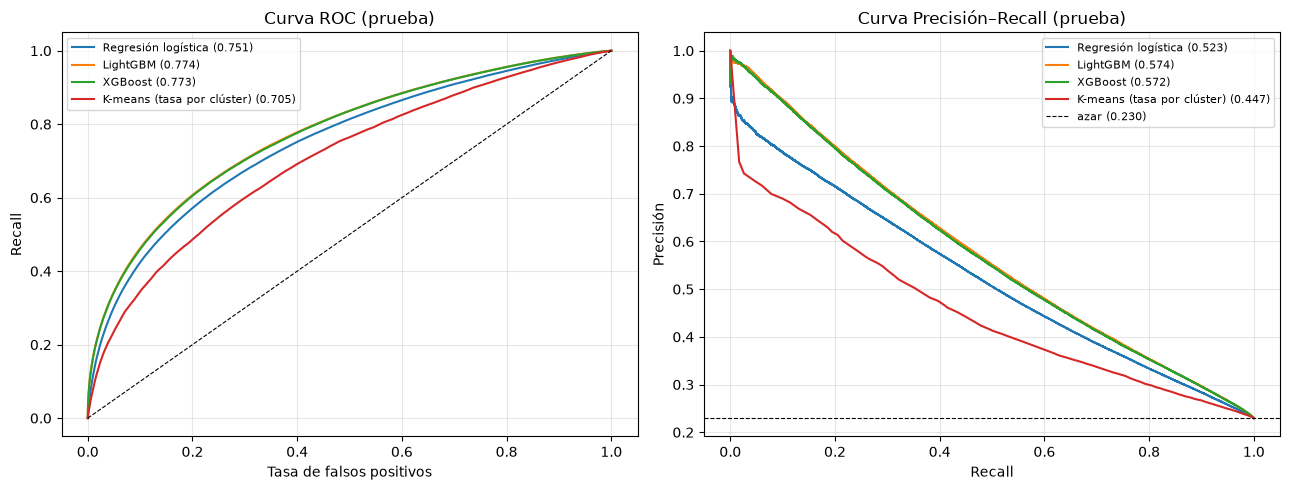

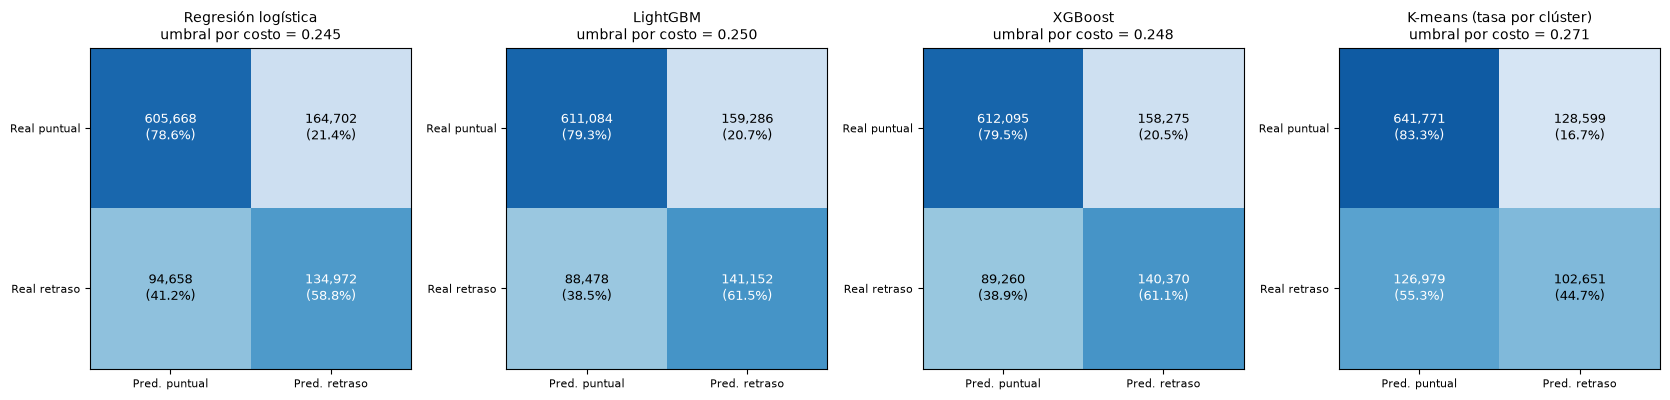

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name in CONTEST:
    p = results[name]["test"]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set(title="Curva ROC (prueba)", xlabel="Tasa de falsos positivos", ylabel="Recall")
ax[1].axhline(prev_test, color="k", ls="--", lw=0.8, label=f"azar ({prev_test:.3f})")
ax[1].set(title="Curva Precisión–Recall (prueba)", xlabel="Recall", ylabel="Precisión")
for a in ax: a.legend(fontsize=8); a.grid(alpha=0.3)
save_fig("roc_pr_curves")

fig, axes = plt.subplots(1, len(CONTEST), figsize=(4.2 * len(CONTEST), 4))
for a, name in zip(np.atleast_1d(axes), CONTEST):
    plot_confusion(a, y_test, results[name]["test"], thr_cost[name], f"{name}\numbral por costo = {thr_cost[name]:.3f}")
save_fig("confusion_matrices")

## 9. Significancia y veredicto: ¿cuál es el mejor modelo?

Regla fija, decidida de antemano:

1. Métrica principal: **PR-AUC en prueba** (no depende del umbral y es la adecuada con clases desbalanceadas).
2. Se calcula, con bootstrap pareado, el **IC 95 % de la diferencia** entre el primero del ranking y cada uno de los otros candidatos.
3. Si el primero **no supera de forma significativa** (el IC incluye 0) a otro candidato, se consideran **empatados**, y entre los empatados se elige el **más simple** (orden: regresión logística, K-means, LightGBM, XGBoost).
4. Si hay un ganador claro, se elige ese.

Solo compiten los 4 candidatos; la ablación y el modelo ponderado son estudios aparte.

In [21]:
SIMPLICITY = ["Regresión logística", "K-means (tasa por clúster)", "LightGBM", "XGBoost"]
pr_test = {n: average_precision_score(y_test, results[n]["test"]) for n in CONTEST}
ranking = sorted(CONTEST, key=lambda n: -pr_test[n])
top = ranking[0]

t0 = time.time()
rows, tied = [], [top]
for other in ranking[1:]:
    d_pr, lo_pr, hi_pr = paired_bootstrap_diff(y_test, results[top]["test"], results[other]["test"], average_precision_score)
    d_roc, lo_roc, hi_roc = paired_bootstrap_diff(y_test, results[top]["test"], results[other]["test"], roc_auc_score)
    significant = lo_pr > 0
    if not significant:
        tied.append(other)
    rows.append({"comparación": f"{top} − {other}", "Δ PR-AUC": d_pr, "IC95 PR-AUC": f"[{lo_pr:+.4f}, {hi_pr:+.4f}]",
                 "Δ ROC-AUC": d_roc, "IC95 ROC-AUC": f"[{lo_roc:+.4f}, {hi_roc:+.4f}]",
                 "¿supera significativamente?": "sí" if significant else "NO (empate)"})
boot_table = pd.DataFrame(rows)
winner = min(tied, key=SIMPLICITY.index)
print(f"Bootstrap listo en {time.time() - t0:,.0f}s ({BOOT_N} remuestreos sobre {min(BOOT_ROWS, len(y_test)):,} filas de prueba)\n")

rank_table = pd.DataFrame({"PR-AUC prueba": pd.Series(pr_test),
                           "ROC-AUC prueba": {n: roc_auc_score(y_test, results[n]["test"]) for n in CONTEST},
                           "Brier prueba": {n: brier_score_loss(y_test, results[n]["test"]) for n in CONTEST},
                           "PR-AUC validación": {n: average_precision_score(y_val, results[n]["val"]) for n in CONTEST}}
                          ).loc[ranking]
display(rank_table)
display(boot_table)

print("=" * 78)
print(f"MEJOR MODELO: {winner}")
print("=" * 78)
print(f"• Primero en PR-AUC de prueba: {top} ({pr_test[top]:.4f}); azar = {prev_test:.4f}.")
if len(tied) > 1:
    print(f"• Empate estadístico (IC95 de la diferencia incluye 0) entre: {', '.join(tied)}.")
    print(f"• Se elige el más simple entre los empatados: {winner}.")
else:
    print(f"• {top} supera de forma significativa a todos los demás candidatos.")
print(f"• {winner}: ROC-AUC {roc_auc_score(y_test, results[winner]['test']):.4f} | "
      f"PR-AUC {pr_test[winner]:.4f} | Brier {brier_score_loss(y_test, results[winner]['test']):.4f}")
print("• Criterio fijado antes de ver resultados: PR-AUC en prueba, bootstrap pareado y parsimonia ante empates.")

WINNER = winner
boot_table.to_csv(OUT_DIR / "bootstrap_differences.csv", index=False)

Bootstrap listo en 74s (100 remuestreos sobre 300,000 filas de prueba)



,PR-AUC prueba,ROC-AUC prueba,Brier prueba,PR-AUC validación
LightGBM,0.5737,0.7740,0.1388,0.5602
XGBoost,0.5715,0.7728,0.1392,0.5581
Regresión logística,0.5226,0.7511,0.1461,0.5098
K-means (tasa por clúster),0.4465,0.7049,0.1566,0.4291


,comparación,Δ PR-AUC,IC95 PR-AUC,Δ ROC-AUC,IC95 ROC-AUC,¿supera significativamente?
0,LightGBM − XGBoost,0.0022,"[+0.0015, +0.0027]",0.0014,"[+0.0011, +0.0017]",sí
1,LightGBM − Regresión logística,0.0496,"[+0.0473, +0.0519]",0.0232,"[+0.0220, +0.0246]",sí
2,LightGBM − K-means (tasa por clúster),0.1265,"[+0.1235, +0.1291]",0.0696,"[+0.0678, +0.0713]",sí


MEJOR MODELO: LightGBM
• Primero en PR-AUC de prueba: LightGBM (0.5737); azar = 0.2296.
• LightGBM supera de forma significativa a todos los demás candidatos.
• LightGBM: ROC-AUC 0.7740 | PR-AUC 0.5737 | Brier 0.1388
• Criterio fijado antes de ver resultados: PR-AUC en prueba, bootstrap pareado y parsimonia ante empates.


## 10. Reentrenar el ganador con entrenamiento + validación

Con el modelo ya elegido, se reentrena con entrenamiento **y** validación (más datos recientes) usando el número de árboles de la parada temprana, y se evalúa en prueba con el **umbral común por costo** (no hay validación limpia para elegir uno). Para ver el efecto, se compara con la versión entrenada solo con entrenamiento al mismo umbral.

In [24]:
refit_summary = None
if RUN_REFIT and models[WINNER]["family"] in ("lr", "lgbm", "xgb"):
    fam = models[WINNER]["family"]
    t0 = time.time()
    if fam == "lr":
        X_all = pd.concat([train[lr_cols].iloc[:n_lr], val[lr_cols]], ignore_index=True)
        y_all = np.r_[y_train[:n_lr], y_val]
        p_refit = make_lr().fit(X_all, y_all).predict_proba(test[lr_cols])[:, 1]
    else:
        feats = models[WINNER]["features"]
        both = pd.concat([train, val], ignore_index=True)
        X_all, y_all = model_matrix(both, feats), both[TARGET].values
        if fam == "lgbm":
            ov = models[WINNER].get("overrides", {})
            m_final = lgb.LGBMClassifier(**{**LGB_PARAMS, **ov, "n_estimators": models[WINNER]["best_iter"]}).fit(X_all, y_all)
            p_refit = m_final.predict_proba(model_matrix(test, feats))[:, 1]
        else:
            m_final = xgb.XGBClassifier(**{**XGB_PARAMS, "n_estimators": models[WINNER]["best_iter"], "early_stopping_rounds": None}).fit(X_all, y_all)
            p_refit = m_final.predict_proba(model_matrix(test, feats))[:, 1]
    before = evaluate_model(f"{WINNER} (solo entrenamiento)", y_test, results[WINNER]["test"], T_COMMON)
    after = evaluate_model(f"{WINNER} (entrenamiento + validación)", y_test, p_refit, T_COMMON)
    refit_summary = pd.DataFrame([before, after]).set_index("modelo")[["roc_auc", "pr_auc", "brier", "log_loss", "ece", "precision", "recall", "f1", "costo_x1000"]]
    results[f"{WINNER} (reentrenado)"] = {"val": results[WINNER]["val"], "test": p_refit}
    print(f"Reentrenado en {time.time() - t0:,.0f}s | umbral común = {T_COMMON:.3f}")
    display(refit_summary)
else:
    print("Reentrenamiento omitido (desactivado o el ganador no es LR / LightGBM / XGBoost).")

Reentrenado en 522s | umbral común = 0.250


,roc_auc,pr_auc,brier,log_loss,ece,precision,recall,f1,costo_x1000
modelo,,,,,,,,,
LightGBM (solo entrenamiento),0.7740,0.5737,0.1388,0.4394,0.0024,0.4703,0.6140,0.5326,424.7090
LightGBM (entrenamiento + validación),0.7770,0.5782,0.1381,0.4373,0.0019,0.4730,0.6186,0.5361,421.0180


## 11. Modelo ganador: priorización, importancia de variables y calibración

In [25]:
print(f"Si solo se puede vigilar el k% de vuelos con mayor riesgo ({WINNER}):")
tk = top_k_table(y_test, results[WINNER]["test"])
display(tk)
tk.to_csv(OUT_DIR / "top_k_priorizacion.csv", index=False)

Si solo se puede vigilar el k% de vuelos con mayor riesgo (LightGBM):


,top_k_%,vuelos,precision,lift,recall_capturado
0,0.0100,10000,0.9553,4.1602,0.0416
1,0.0500,50000,0.8193,3.5679,0.1784
2,0.1000,100000,0.7035,3.0638,0.3064
3,0.2000,200000,0.5603,2.4401,0.4880
4,0.3000,300000,0.4701,2.0474,0.6142


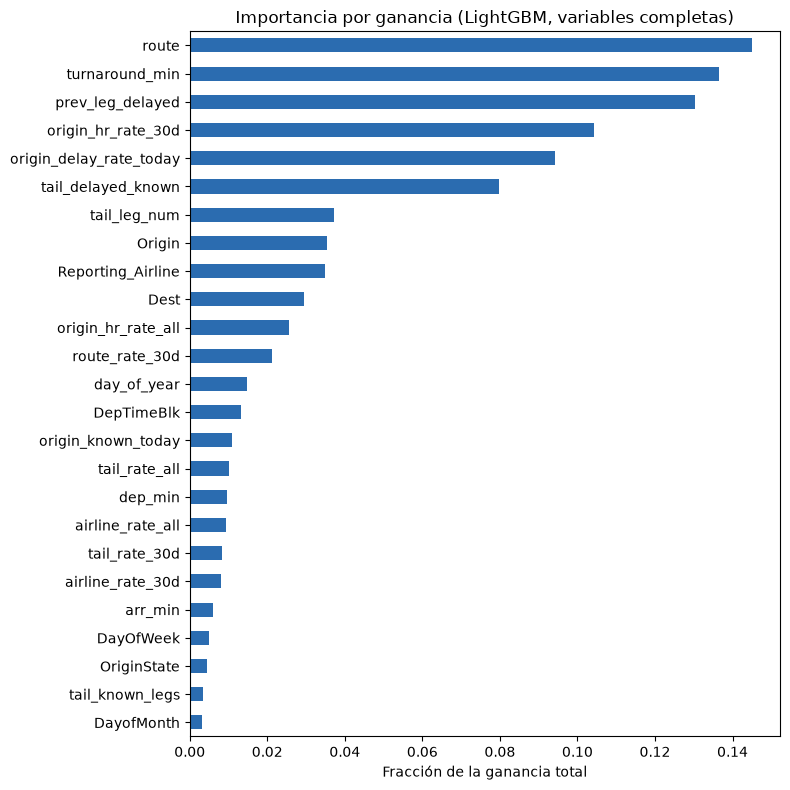

In [26]:
# Importancia por ganancia del LightGBM completo (referencia de qué variables aportan).
imp = pd.Series(m_lgbm.booster_.feature_importance("gain"), index=FULL_FEATURES).sort_values()
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(8, 8))
imp.tail(25).plot.barh(ax=ax, color="#2b6cb0")
ax.set(title="Importancia por ganancia (LightGBM, variables completas)", xlabel="Fracción de la ganancia total")
save_fig("feature_importance")

,sin calibrar,isotónica
brier,0.1388,0.1389
log_loss,0.4394,0.4395
ece,0.0024,0.0033


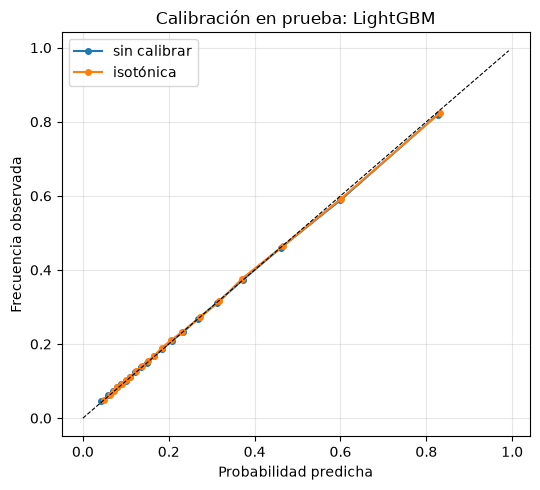

In [27]:
# Calibración (isotónica) del ganador: se ajusta en VALIDACIÓN y se evalúa en PRUEBA.
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(results[WINNER]["val"], y_val)
p_raw, p_cal = results[WINNER]["test"], iso.predict(results[WINNER]["test"])

calib = pd.DataFrame({
    "sin calibrar": [brier_score_loss(y_test, p_raw), log_loss(y_test, np.clip(p_raw, 1e-6, 1 - 1e-6)), expected_calibration_error(y_test, p_raw)],
    "isotónica":    [brier_score_loss(y_test, p_cal), log_loss(y_test, np.clip(p_cal, 1e-6, 1 - 1e-6)), expected_calibration_error(y_test, p_cal)],
}, index=["brier", "log_loss", "ece"])
display(calib)

fig, ax = plt.subplots(figsize=(5.5, 5))
for label, p in [("sin calibrar", p_raw), ("isotónica", p_cal)]:
    d = pd.DataFrame({"y": y_test, "p": p}); d["bin"] = pd.qcut(d.p, 20, duplicates="drop")
    g = d.groupby("bin", observed=True).agg(pred=("p", "mean"), obs=("y", "mean"))
    ax.plot(g.pred, g.obs, marker="o", ms=4, label=label)
lim = max(p_raw.max(), 0.6); ax.plot([0, lim], [0, lim], "k--", lw=0.8)
ax.set(title=f"Calibración en prueba: {WINNER}", xlabel="Probabilidad predicha", ylabel="Frecuencia observada"); ax.legend(); ax.grid(alpha=0.3)
save_fig("calibration")

In [28]:
# ============ 11b. Análisis por subgrupos (modelo ganador, tramo de prueba) ============
MODEL_NAME = WINNER
P_TEST = results[WINNER]["test"]    # para analizar el modelo ajustado: reemplazar por sus probabilidades de prueba
THR    = thr_cost[WINNER]           # umbral por costo elegido en VALIDACIÓN
MIN_ROWS = 2000                     # subgrupos con menos filas de prueba no se interpretan
N_TOP_AIRPORTS = 20                 # aeropuertos de origen con más vuelos en la prueba

sub = test[["Reporting_Airline", "Origin", "dep_hour", "Month"]].copy()
sub["y"], sub["p"] = y_test, P_TEST
sub["Temporada"] = sub.Month.map(lambda m: "Invierno (dic–feb)" if m in (12, 1, 2) else
                                 "Primavera (mar–may)" if m in (3, 4, 5) else
                                 "Verano (jun–ago)" if m in (6, 7, 8) else "Otoño (sep–nov)")
sub["Franja horaria"] = pd.cut(sub.dep_hour, [-1, 5, 11, 17, 24],
                               labels=["Madrugada (0–5 h)", "Mañana (6–11 h)", "Tarde (12–17 h)", "Noche (18–24 h)"])
sub = sub.rename(columns={"Reporting_Airline": "Aerolínea", "Origin": "Aeropuerto de origen"})

def subgroup_metrics(df, by):
    rows = []
    for key, g in df.groupby(by, observed=True):
        if len(g) < MIN_ROWS or g.y.nunique() < 2:
            continue
        pred = (g.p >= THR).astype(int)
        tp = int(((pred == 1) & (g.y == 1)).sum()); fp = int(((pred == 1) & (g.y == 0)).sum()); fn = int(((pred == 0) & (g.y == 1)).sum())
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        rows.append({by: key, "vuelos": len(g), "tasa_real": g.y.mean(), "tasa_predicha": g.p.mean(),
                     "sesgo (pred/real)": g.p.mean() / g.y.mean(),
                     "roc_auc": roc_auc_score(g.y, g.p), "pr_auc": average_precision_score(g.y, g.p),
                     "lift_pr_auc": average_precision_score(g.y, g.p) / g.y.mean(),
                     "precision": prec, "recall": rec, "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
                     "alertas_%": pred.mean(), "brier": brier_score_loss(g.y, g.p)})
    return pd.DataFrame(rows).set_index(by)

overall = {"vuelos": len(sub), "tasa_real": sub.y.mean(), "roc_auc": roc_auc_score(sub.y, sub.p),
           "pr_auc": average_precision_score(sub.y, sub.p), "lift_pr_auc": average_precision_score(sub.y, sub.p) / sub.y.mean(),
           "sesgo": sub.p.mean() / sub.y.mean()}
print(f"Modelo: {MODEL_NAME} | umbral por costo = {THR:.3f}")
print(f"Global (prueba): ROC-AUC {overall['roc_auc']:.4f} | PR-AUC {overall['pr_auc']:.4f} | lift PR-AUC {overall['lift_pr_auc']:.2f} | tasa de retraso {overall['tasa_real']:.2%} | sesgo global (pred/real) {overall['sesgo']:.2f}")

Modelo: LightGBM | umbral por costo = 0.250
Global (prueba): ROC-AUC 0.7740 | PR-AUC 0.5737 | lift PR-AUC 2.50 | tasa de retraso 22.96% | sesgo global (pred/real) 1.00


In [29]:
top_ap = sub["Aeropuerto de origen"].value_counts().head(N_TOP_AIRPORTS).index
groups = {
    "Aerolínea": subgroup_metrics(sub, "Aerolínea").sort_values("pr_auc"),
    "Franja horaria": subgroup_metrics(sub, "Franja horaria"),
    "Temporada": subgroup_metrics(sub, "Temporada"),
    "Aeropuerto de origen": subgroup_metrics(sub[sub["Aeropuerto de origen"].isin(top_ap)], "Aeropuerto de origen").sort_values("pr_auc"),
}
for name, tab in groups.items():
    print(f"\n=== {name} ===")
    display(tab)
    tab.to_csv(OUT_DIR / f"subgrupos_{name.lower().replace(' ', '_').replace('é', 'e').replace('ó', 'o')}.csv")


=== Aerolínea ===


,vuelos,tasa_real,tasa_predicha,sesgo (pred/real),roc_auc,pr_auc,lift_pr_auc,precision,recall,f1,alertas_%,brier
Aerolínea,,,,,,,,,,,,
AS,44175,0.2045,0.2065,1.0100,0.7168,0.4268,2.0872,0.3932,0.4920,0.4371,0.2558,0.1446
HA,3772,0.1819,0.1460,0.8028,0.7606,0.4492,2.4701,0.4386,0.3907,0.4133,0.1620,0.1280
MQ,45318,0.1812,0.1888,1.0418,0.7422,0.4753,2.6229,0.4254,0.4954,0.4577,0.2111,0.1241
DL,148100,0.1844,0.1857,1.0073,0.7458,0.4795,2.6006,0.4277,0.4957,0.4592,0.2137,0.1254
UA,118987,0.1877,0.1853,0.9875,0.7533,0.4968,2.6469,0.4429,0.4963,0.4681,0.2103,0.1256
YX,50080,0.1921,0.1679,0.8739,0.7519,0.4996,2.6010,0.4990,0.4516,0.4741,0.1738,0.1279
OO,121510,0.1953,0.1898,0.9719,0.7716,0.5370,2.7494,0.5045,0.5123,0.5083,0.1983,0.1243
F9,30059,0.2680,0.2820,1.0522,0.7392,0.5596,2.0881,0.4284,0.6804,0.5258,0.4256,0.1628
OH,33372,0.2664,0.2587,0.9711,0.7688,0.6023,2.2611,0.5022,0.6444,0.5645,0.3418,0.1534



=== Franja horaria ===


,vuelos,tasa_real,tasa_predicha,sesgo (pred/real),roc_auc,pr_auc,lift_pr_auc,precision,recall,f1,alertas_%,brier
Franja horaria,,,,,,,,,,,,
Madrugada (0–5 h),29412,0.0843,0.0911,1.0802,0.6511,0.1663,1.9717,0.2758,0.0980,0.1446,0.0300,0.0749
Mañana (6–11 h),396349,0.1384,0.1395,1.0081,0.7046,0.3734,2.6977,0.4273,0.2826,0.3402,0.0916,0.1049
Tarde (12–17 h),355111,0.2781,0.2721,0.9786,0.7554,0.5938,2.1353,0.4631,0.6757,0.5496,0.4057,0.1618
Noche (18–24 h),219128,0.3355,0.3415,1.0178,0.7787,0.6687,1.9930,0.4923,0.7980,0.6089,0.5439,0.1716



=== Temporada ===


,vuelos,tasa_real,tasa_predicha,sesgo (pred/real),roc_auc,pr_auc,lift_pr_auc,precision,recall,f1,alertas_%,brier
Temporada,,,,,,,,,,,,
Invierno (dic–feb),230641,0.2262,0.2367,1.0463,0.7564,0.5475,2.4201,0.4356,0.6129,0.5092,0.3183,0.1415
Otoño (sep–nov),248109,0.1871,0.1771,0.9465,0.7649,0.5151,2.7537,0.4748,0.4843,0.4795,0.1908,0.1227
Primavera (mar–may),259392,0.2261,0.2327,1.0289,0.7706,0.5655,2.5007,0.4570,0.6176,0.5253,0.3056,0.1383
Verano (jun–ago),261858,0.2764,0.2696,0.9752,0.7873,0.6334,2.2916,0.5026,0.6972,0.5841,0.3834,0.1524



=== Aeropuerto de origen ===


,vuelos,tasa_real,tasa_predicha,sesgo (pred/real),roc_auc,pr_auc,lift_pr_auc,precision,recall,f1,alertas_%,brier
Aeropuerto de origen,,,,,,,,,,,,
SLC,16958,0.1582,0.1636,1.0346,0.7582,0.4643,2.9360,0.4303,0.4571,0.4433,0.1680,0.1099
IAH,16973,0.2047,0.2133,1.0423,0.7298,0.4847,2.3683,0.4003,0.5325,0.4570,0.2723,0.1381
MSP,16297,0.1955,0.1928,0.9861,0.7593,0.5185,2.6524,0.4542,0.5201,0.4849,0.2238,0.1273
SEA,23681,0.2161,0.2163,1.0012,0.7592,0.5372,2.4860,0.4577,0.5626,0.5048,0.2656,0.1369
DTW,17288,0.2194,0.2171,0.9894,0.7540,0.5400,2.4614,0.4615,0.5668,0.5088,0.2695,0.1384
EWR,17172,0.1981,0.2021,1.0205,0.7716,0.5402,2.7276,0.4502,0.5587,0.4986,0.2457,0.1260
LAX,27080,0.2075,0.2084,1.0042,0.7682,0.5536,2.6681,0.4573,0.5579,0.5026,0.2531,0.1298
ATL,45031,0.2188,0.2233,1.0209,0.7739,0.5577,2.5495,0.4585,0.6171,0.5261,0.2944,0.1350
MIA,15858,0.2568,0.2739,1.0666,0.7560,0.5700,2.2198,0.4163,0.7100,0.5249,0.4379,0.1552


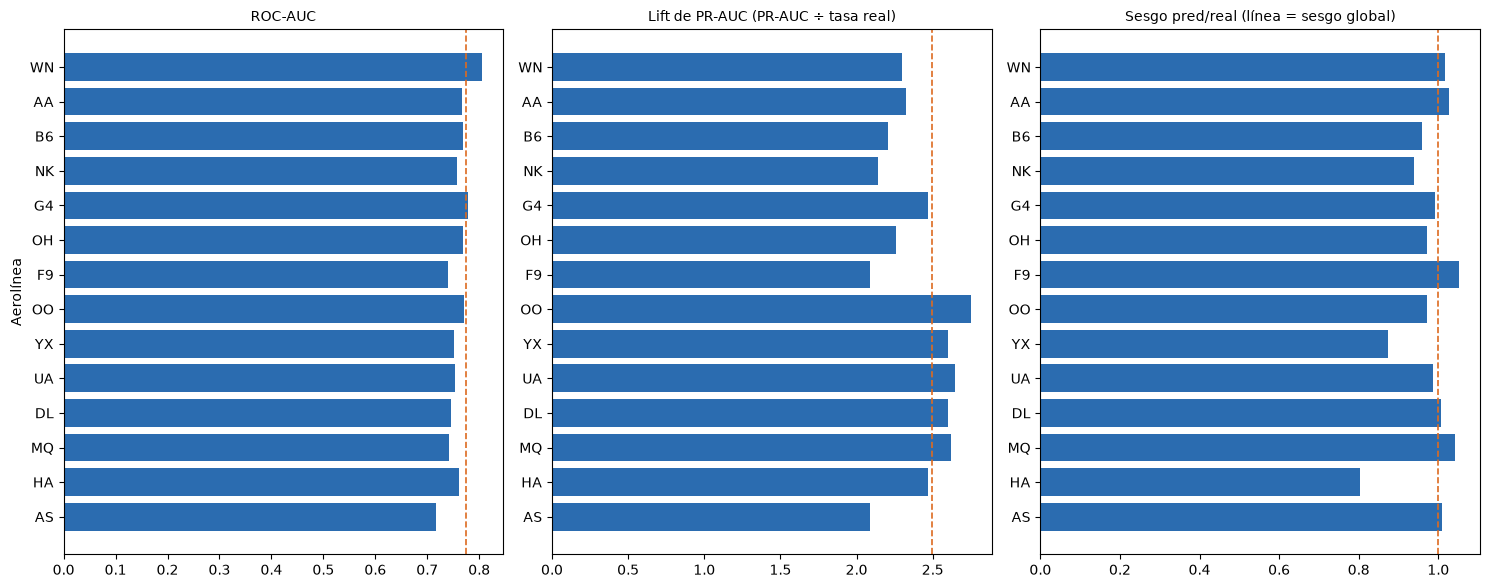

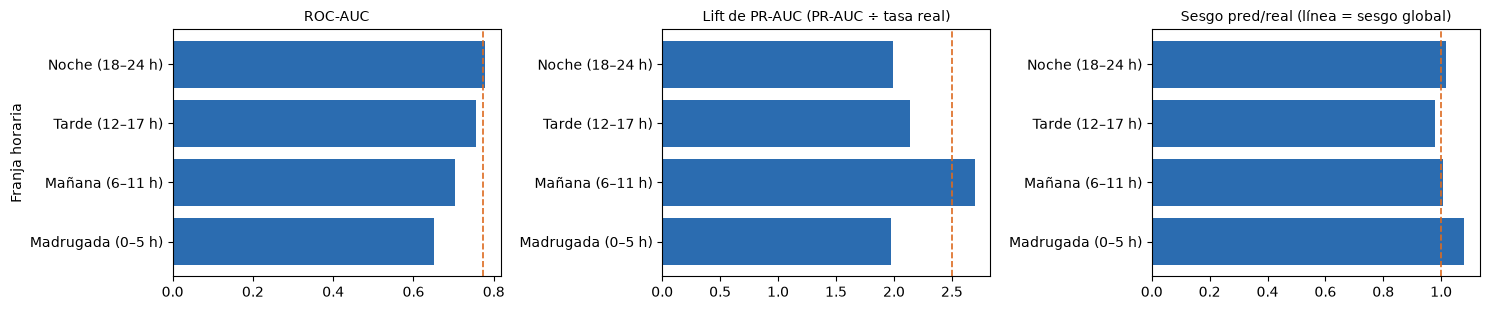

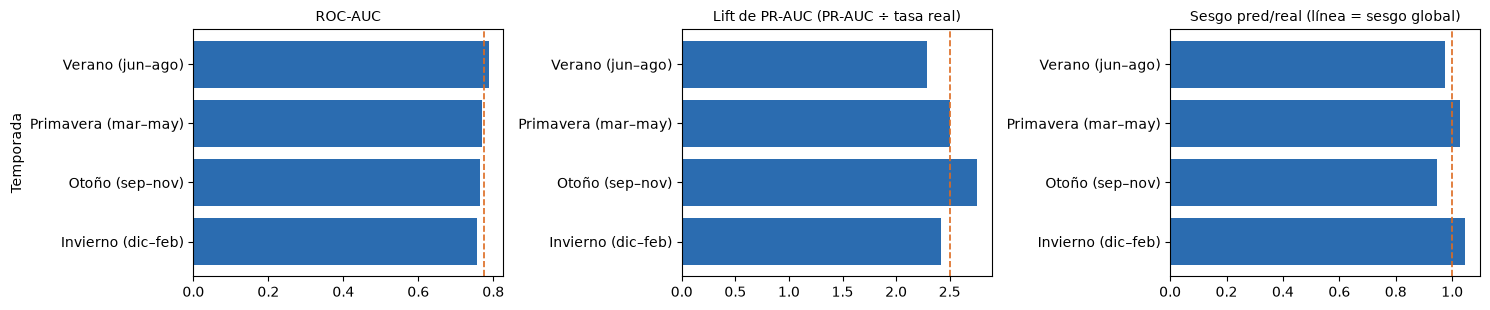

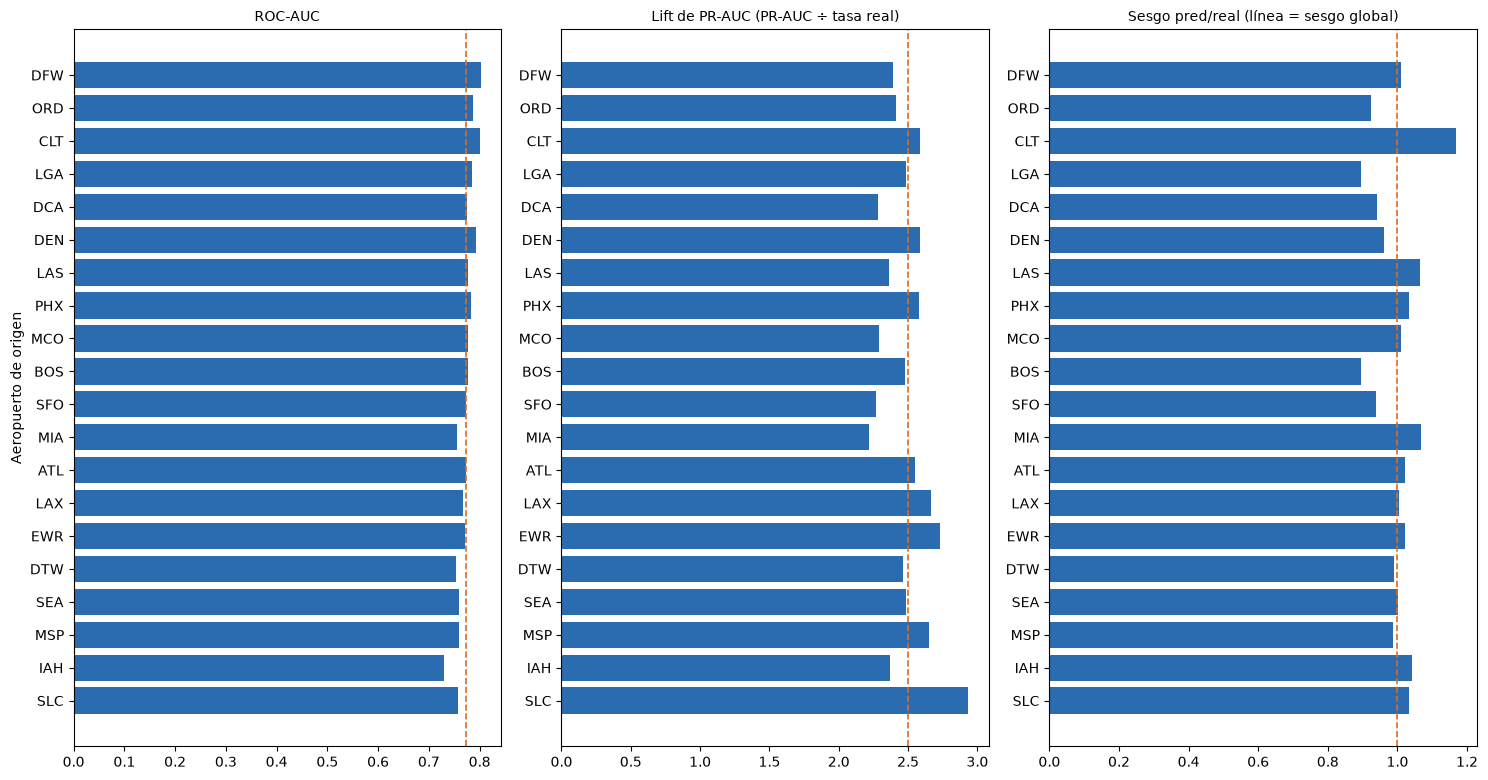

In [30]:
# Lectura: ROC-AUC no depende de la tasa del subgrupo; el sesgo se compara con el sesgo GLOBAL (la deriva temporal sesga a todos por igual); PR-AUC sí depende
for name, tab in groups.items():
    fig, ax = plt.subplots(1, 3, figsize=(15, max(3.2, 0.32 * len(tab) + 1.5)))
    for a, col, ref, ttl in [(ax[0], "roc_auc", overall["roc_auc"], "ROC-AUC"),
                             (ax[1], "lift_pr_auc", overall["lift_pr_auc"], "Lift de PR-AUC (PR-AUC ÷ tasa real)"),
                             (ax[2], "sesgo (pred/real)", overall["sesgo"], "Sesgo pred/real (línea = sesgo global)")]:
        a.barh(tab.index.astype(str), tab[col], color="#2b6cb0")
        a.axvline(ref, color="#dd6b20", ls="--", lw=1.2)
        a.set_title(ttl, fontsize=10); a.grid(axis="y", visible=False)
    ax[0].set_ylabel(name)
    save_fig(f"subgrupos_{name.lower().replace(' ', '_').replace('é', 'e').replace('ó', 'o')}")

In [31]:
# Subgrupos donde el modelo falla o está mal calibrado (umbrales ajustables).
DROP_ROC, DROP_LIFT, BIAS_TOL = 0.03, 0.15, 0.10

flags = []
for name, tab in groups.items():
    for key, r in tab.iterrows():
        motivos = []
        if r.roc_auc < overall["roc_auc"] - DROP_ROC:
            motivos.append(f"ROC-AUC {r.roc_auc:.3f} (global {overall['roc_auc']:.3f})")
        if r.lift_pr_auc < overall["lift_pr_auc"] * (1 - DROP_LIFT):
            motivos.append(f"lift PR-AUC {r.lift_pr_auc:.2f} (global {overall['lift_pr_auc']:.2f})")
        rel = r["sesgo (pred/real)"] / overall["sesgo"] - 1      # desviación respecto al sesgo global
        if abs(rel) > BIAS_TOL:
            motivos.append(f"sesgo {r['sesgo (pred/real)']:.2f} vs global {overall['sesgo']:.2f} "
                           f"({'sobreestima' if rel > 0 else 'subestima'} más que el resto)")
        if motivos:
            flags.append({"dimensión": name, "subgrupo": str(key), "vuelos": int(r.vuelos), "motivo": "; ".join(motivos)})
flags = pd.DataFrame(flags)
print(f"Subgrupos señalados: {len(flags)} de {sum(len(t) for t in groups.values())} evaluados "
      f"(ROC-AUC < global − {DROP_ROC}, lift < global − {DROP_LIFT:.0%}, o sesgo a más de {BIAS_TOL:.0%} del sesgo global)")
display(flags if len(flags) else "Ningún subgrupo supera los umbrales.")
if len(flags):
    flags.to_csv(OUT_DIR / "subgrupos_senalados.csv", index=False)

Subgrupos señalados: 12 de 42 evaluados (ROC-AUC < global − 0.03, lift < global − 15%, o sesgo a más de 10% del sesgo global)


,dimensión,subgrupo,vuelos,motivo
0,Aerolínea,AS,44175,ROC-AUC 0.717 (global 0.774); lift PR-AUC 2.09...
1,Aerolínea,HA,3772,sesgo 0.80 vs global 1.00 (subestima más que e...
2,Aerolínea,MQ,45318,ROC-AUC 0.742 (global 0.774)
3,Aerolínea,YX,50080,sesgo 0.87 vs global 1.00 (subestima más que e...
4,Aerolínea,F9,30059,ROC-AUC 0.739 (global 0.774); lift PR-AUC 2.09...
5,Franja horaria,Madrugada (0–5 h),29412,ROC-AUC 0.651 (global 0.774); lift PR-AUC 1.97...
6,Franja horaria,Mañana (6–11 h),396349,ROC-AUC 0.705 (global 0.774)
7,Franja horaria,Noche (18–24 h),219128,lift PR-AUC 1.99 (global 2.50)
8,Aeropuerto de origen,IAH,16973,ROC-AUC 0.730 (global 0.774)
9,Aeropuerto de origen,BOS,20324,sesgo 0.90 vs global 1.00 (subestima más que e...


## 12. Diagnóstico de deriva temporal

¿El empate entre la regresión logística y LightGBM se debe a la **deriva** (la tasa de retraso cambia entre entrenamiento y prueba) o a que las variables ya capturan casi toda la señal?

Se repite la comparación en una configuración con menos deriva: entrenar con 2022-03 → 2023-06, validar (parada temprana) en 2023-07 → 2023-12 y evaluar en 2024. **Cómo leerlo:** si LightGBM le saca ventaja clara a la logística *aquí* pero no en la prueba principal, la deriva explica el empate; si siguen empatados, la causa son las variables, no el modelo.

In [32]:
diag_summary = None
if RUN_DIAG:
    t0 = time.time()
    dtr = build_split(f"FlightDate >= DATE '{d0.date()}' AND FlightDate <= DATE '2023-06-30'", N_DIAG_TRAIN)
    dva = build_split("FlightDate >= DATE '2023-07-01' AND FlightDate <= DATE '2023-12-31'", N_DIAG_EVAL)
    dte = build_split("FlightDate >= DATE '2024-01-01' AND FlightDate <= DATE '2024-12-31'", N_DIAG_EVAL)
    n_d = min(N_LOGREG, len(dtr)) if N_LOGREG else len(dtr)
    lr_d = make_lr().fit(dtr[lr_cols].iloc[:n_d], dtr[TARGET].values[:n_d])
    lgb_d = fit_lgbm(FULL_FEATURES, dtr, dva)
    yd = dte[TARGET].values
    out = {"Regresión logística": lr_d.predict_proba(dte[lr_cols])[:, 1],
           "LightGBM": predict_lgbm(lgb_d, dte, FULL_FEATURES)}
    diag_summary = pd.DataFrame({n: {"ROC-AUC": roc_auc_score(yd, p), "PR-AUC": average_precision_score(yd, p),
                                     "Brier": brier_score_loss(yd, p)} for n, p in out.items()}).T
    diag_summary["tasa retraso entren."] = dtr[TARGET].mean()
    diag_summary["tasa retraso eval."] = yd.mean()
    print(f"Diagnóstico listo en {time.time() - t0:,.0f}s ({len(dtr):,} / {len(dva):,} / {len(dte):,} filas)")
    display(diag_summary)
    d_gap = diag_summary.loc["LightGBM", "PR-AUC"] - diag_summary.loc["Regresión logística", "PR-AUC"]
    m_gap = pr_test["LightGBM"] - pr_test["Regresión logística"]
    print(f"Ventaja de LightGBM sobre la logística en PR-AUC: diagnóstico {d_gap:+.4f} | prueba principal {m_gap:+.4f}")

Diagnóstico listo en 147s (1,500,000 / 500,000 / 500,000 filas)


,ROC-AUC,PR-AUC,Brier,tasa retraso entren.,tasa retraso eval.
Regresión logística,0.7449,0.4900,0.1370,0.2173,0.2065
LightGBM,0.7644,0.5377,0.1312,0.2173,0.2065


Ventaja de LightGBM sobre la logística en PR-AUC: diagnóstico +0.0477 | prueba principal +0.0511


## 13. Guardar artefactos

In [ ]:
m_lgbm.booster_.save_model(str(OUT_DIR / "lgbm_completo.txt"))
pd.concat([tab_thr.assign(umbral_tipo="costo (validación)"), tab_common.assign(umbral_tipo="común teórico")]).to_csv(OUT_DIR / "model_comparison_full.csv")
verdict = {
    "mejor_modelo": WINNER, "primero_en_pr_auc": top, "empatados": tied,
    "criterio": "PR-AUC en prueba; bootstrap pareado IC95; parsimonia ante empate",
    "pr_auc_prueba": {n: float(v) for n, v in pr_test.items()},
}
with open(OUT_DIR / "veredicto.json", "w") as f:
    json.dump(verdict, f, indent=2, ensure_ascii=False)
with open(OUT_DIR / "run_config.json", "w") as f:
    json.dump({"train_end": TRAIN_END, "val_end": VAL_END, "warmup_days": WARMUP_DAYS,
               "n_train": len(train), "n_val": len(val), "n_test": len(test),
               "pred_horizon_min": PRED_HORIZON_MIN, "cost_fp": COST_FP, "cost_fn": COST_FN,
               "hist_window_days": HIST_WINDOW_DAYS, "hist_smooth": HIST_SMOOTH, "prior": PRIOR, "seed": SEED,
               "features_full": FULL_FEATURES, "thresholds_cost_val": thr_cost, "k_means_k": best_k}, f, indent=2)
print("Guardado en", OUT_DIR.resolve())

Guardado en C:\Users\Usuario\OneDrive\Escritorio\Ciencia_de_datos\Proyecto Integrador\Missed-Flight-Risk-Percentage-Analysis-US\outputs\outputs_modeling


: 

## Supuestos y pendientes

- Las muestras son un subconjunto (`N_TRAIN`, `N_EVAL`); subirlas mejora sobre todo a los modelos de árboles.
- Sin ajuste fino de hiperparámetros (la propuesta lo contempla en *Modelado*).